In [1]:
import pandas as pd
import numpy as np

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv(r"D:\D DRIVE DOWNLOADS\zr7vgbcyr2-1\metadata.csv")

In [4]:
data.tail()

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
2293,PAT_1708,3156,NaN,NaN,NaN,NaN,73,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1708_3156_175.png,False
2294,PAT_46,880,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,12.0,BCC,True,True,False,True,False,False,PAT_46_880_140.png,True
2295,PAT_1343,1217,NaN,NaN,NaN,NaN,74,NaN,NaN,NaN,...,NaN,SEK,False,False,False,False,False,False,PAT_1343_1217_404.png,False
2296,PAT_326,690,False,False,POMERANIA,POMERANIA,58,True,FEMALE,True,...,4.0,BCC,True,False,False,False,False,True,PAT_326_690_823.png,True
2297,PAT_1714,3189,NaN,NaN,NaN,NaN,41,NaN,NaN,NaN,...,NaN,SEK,False,True,False,False,False,True,PAT_1714_3189_989.png,False


In [5]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           2298 non-null   str    
 1   lesion_id            2298 non-null   int64  
 2   smoke                1494 non-null   object 
 3   drink                1494 non-null   object 
 4   background_father    1480 non-null   str    
 5   background_mother    1476 non-null   str    
 6   age                  2298 non-null   int64  
 7   pesticide            1494 non-null   object 
 8   gender               1494 non-null   str    
 9   skin_cancer_history  1494 non-null   object 
 10  cancer_history       1494 non-null   object 
 11  has_piped_water      1494 non-null   object 
 12  has_sewage_system    1494 non-null   object 
 13  fitspatrick          1494 non-null   float64
 14  region               2298 non-null   str    
 15  diameter_1           1494 non-null   float64
 16 

In [6]:
data["patient_id"].nunique()

1373

In [7]:
data["patient_id"].value_counts().head()

patient_id
PAT_645     10
PAT_330     10
PAT_388     10
PAT_53       7
PAT_1414     7
Name: count, dtype: int64

In [8]:
patient_counts = data['patient_id'].value_counts()

print(patient_counts.describe())
print(patient_counts.head(20))

count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
Name: count, dtype: float64
patient_id
PAT_645     10
PAT_330     10
PAT_388     10
PAT_53       7
PAT_1414     7
PAT_747      7
PAT_691      7
PAT_115      7
PAT_270      7
PAT_46       6
PAT_38       6
PAT_380      6
PAT_492      6
PAT_771      6
PAT_63       6
PAT_267      6
PAT_93       6
PAT_1364     6
PAT_108      6
PAT_677      6
Name: count, dtype: int64


In [9]:
data = data.sort_values(by = 'patient_id').reset_index(drop=True)

In [10]:
data

,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_10,18,True,False,GERMANY,GERMANY,69,False,MALE,False,...,9.0,SCC,True,UNK,False,UNK,False,True,PAT_10_18_830.png,True
1,PAT_100,393,False,False,POMERANIA,POMERANIA,14,False,MALE,False,...,3.0,NEV,False,False,False,False,False,False,PAT_100_393_898.png,True
2,PAT_100,393,False,False,POMERANIA,POMERANIA,14,False,MALE,False,...,3.0,NEV,False,False,False,False,False,False,PAT_100_393_595.png,True
3,PAT_1000,31,NaN,NaN,NaN,NaN,65,NaN,NaN,NaN,...,NaN,SEK,False,False,False,False,False,False,PAT_1000_31_620.png,False
4,PAT_1006,53,NaN,NaN,NaN,NaN,63,NaN,NaN,NaN,...,NaN,ACK,False,False,False,False,False,False,PAT_1006_53_716.png,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2293,PAT_998,17,NaN,NaN,NaN,NaN,50,NaN,NaN,NaN,...,NaN,SEK,False,True,False,False,False,False,PAT_998_17_641.png,False
2294,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_223.png,False
2295,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_540.png,False
2296,PAT_999,20,NaN,NaN,NaN,NaN,40,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,True,False,PAT_999_20_583.png,False


In [11]:
data["diagnostic"] = data["diagnostic"].replace({
    "BOD" : "SCC",
})

In [12]:
data["diagnostic"].value_counts()

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [13]:
diagnostic_counts = data["diagnostic"].value_counts()
diagnostic_counts

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [14]:
diagnosis_percentage = (
    data['diagnostic']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print(diagnosis_percentage)

diagnostic
BCC    36.77
ACK    31.77
NEV    10.62
SEK    10.23
SCC     8.36
MEL     2.26
Name: proportion, dtype: float64


Text(0.5, 1.0, 'Distribution of diagnostic classes')

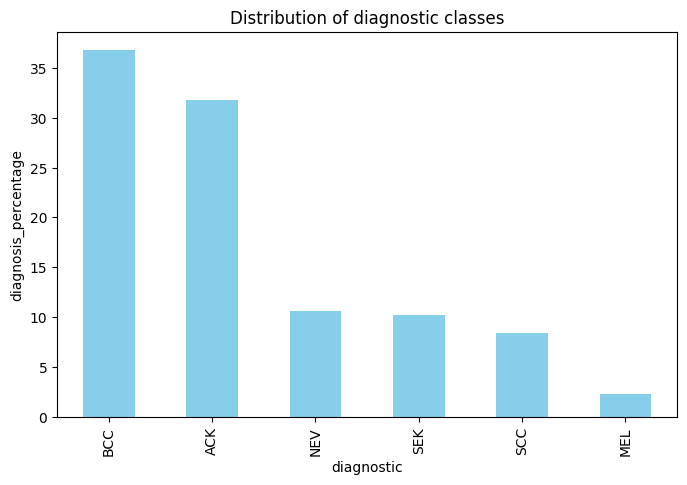

In [15]:
diagnosis_percentage.plot(
    kind = 'bar',
    figsize =(8,5),
    color='skyblue',
)
plt.xlabel("diagnostic")
plt.ylabel("diagnosis_percentage")
plt.title("Distribution of diagnostic classes")

In [16]:
data['diagnostic'].value_counts()

diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52
Name: count, dtype: int64

In [17]:
import pandas as pd
from scipy.stats import chi2_contingency

def chi_square_test(data, feature, target='diagnostic'):
    contingency = pd.crosstab(data[feature], data[target])
    chi2, p, dof, expected = chi2_contingency(contingency)
    
    # Cramér's V for effect size
    n = contingency.sum().sum()
    min_dim = min(contingency.shape) - 1
    cramers_v = (chi2 / (n * min_dim)) ** 0.5
    
    return {
        'feature': feature,
        'chi2': round(chi2, 2),
        'p_value': p,
        'cramers_v': round(cramers_v, 3),
        'significant': p < 0.05
    }

# list all your categorical features here
categorical_features = ['itch', 'grew', 'hurt', 'changed', 'elevation', 'bleed',
                         'cancer_history', 'skin_cancer_history', 'smoke', 'drink',
                         'background_father', 'background_mother', 'gender',
                         'region', 'pesticide', 'biopsed']  # keep biopsed in for now just to see, but don't use it as an input feature later

results = []
for feat in categorical_features:
    if feat in data.columns:
        results.append(chi_square_test(data, feat, target='diagnostic'))

results_df = pd.DataFrame(results).sort_values('cramers_v', ascending=False)
print(results_df)

                feature     chi2        p_value  cramers_v  significant
15              biopsed  1499.94   0.000000e+00      0.808         True
1                  grew   855.71  2.160752e-177      0.431         True
0                  itch   654.96  2.905929e-134      0.378         True
3               changed   653.57  5.783800e-134      0.377         True
4             elevation   651.17  1.885568e-133      0.376         True
5                 bleed   581.74  1.435794e-118      0.356         True
13               region   987.84  5.093887e-165      0.293         True
2                  hurt   374.50   2.495937e-74      0.285         True
14            pesticide    31.44   7.663615e-06      0.145         True
8                 smoke    29.43   1.910254e-05      0.140         True
10    background_father   104.46   3.331274e-04      0.119         True
11    background_mother    75.36   1.171644e-02      0.101         True
12               gender    12.22   3.194504e-02      0.090      

In [18]:
data['cancer_binary'] = data['diagnostic'].map({
    'BCC':'Cancer','SCC':'Cancer','MEL':'Cancer',
    'ACK':'Non-cancer','NEV':'Non-cancer','SEK':'Non-cancer'
})

for feat in ['cancer_history','skin_cancer_history']:
    ct = pd.crosstab(data[feat], data['cancer_binary'])
    chi2, p, dof, exp = chi2_contingency(ct)
    print(feat, 'p =', p)

cancer_history p = 0.8772859466160792
skin_cancer_history p = 0.1255592993129681


In [19]:
data['cancer_history'].value_counts(normalize=True)


cancer_history
True     0.521419
False    0.478581
Name: proportion, dtype: float64

In [20]:
from scipy.stats import kruskal

# split age values by diagnostic group
groups = [data[data['diagnostic'] == d]['age'].dropna() for d in data['diagnostic'].unique()]

stat, p_value = kruskal(*groups)
print(f"Kruskal-Wallis H-statistic: {stat:.2f}, p-value: {p_value}")

Kruskal-Wallis H-statistic: 480.77, p-value: 1.1272543664668308e-101


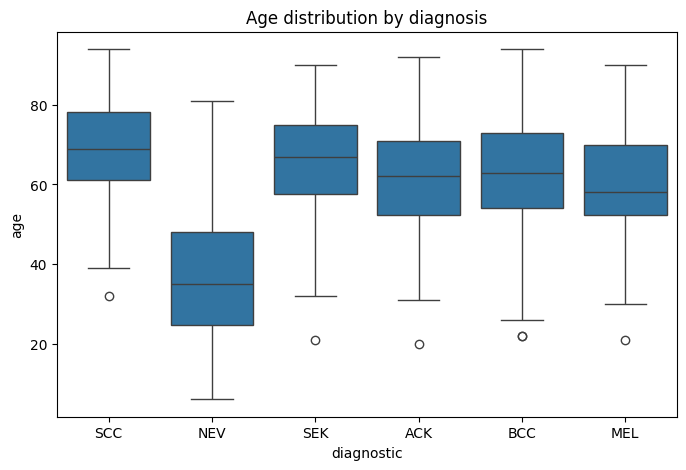

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.boxplot(x='diagnostic', y='age', data=data)
plt.title('Age distribution by diagnosis')
plt.show()

In [22]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

# your finalized features
features = ['grew', 'itch', 'changed', 'elevation', 'bleed', 'region', 'hurt', 'age']
target = 'diagnostic'

# patient-grouped split (avoid leakage)
patients = data['patient_id'].unique()
patients = np.asarray(patients)
train_patients, test_patients = train_test_split(patients, test_size=0.2, random_state=42)

train_df = data[data['patient_id'].isin(train_patients)].copy()
test_df = data[data['patient_id'].isin(test_patients)].copy()

# encode target
le = LabelEncoder()
train_df['target_enc'] = le.fit_transform(train_df[target])
test_df['target_enc'] = le.transform(test_df[target])

# one-hot encode categorical features (region, itch, grew, etc. if stored as strings/bools)
X_train = pd.get_dummies(train_df[features], dummy_na=True)
X_test = pd.get_dummies(test_df[features], dummy_na=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)  # align columns

y_train = train_df['target_enc']
y_test = test_df['target_enc']

print(X_train.shape, X_test.shape)

(1837, 40) (461, 40)


In [23]:
pip install xgboost 

Note: you may need to restart the kernel to use updated packages.


In [24]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    objective='multi:softmax',
    num_class=len(le.classes_),
    eval_metric='mlogloss',
    random_state=42
)
xgb_model.fit(X_train, y_train)

xgb_preds = xgb_model.predict(X_test)
print("=== XGBoost ===")
print("Accuracy:", accuracy_score(y_test, xgb_preds))
print(classification_report(y_test, xgb_preds, target_names=le.classes_))

=== XGBoost ===
Accuracy: 0.6594360086767896
              precision    recall  f1-score   support

         ACK       0.77      0.78      0.77       127
         BCC       0.70      0.76      0.73       174
         MEL       0.20      0.29      0.24         7
         NEV       0.68      0.80      0.74        49
         SCC       0.25      0.16      0.20        49
         SEK       0.52      0.42      0.46        55

    accuracy                           0.66       461
   macro avg       0.52      0.53      0.52       461
weighted avg       0.64      0.66      0.65       461



In [25]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',  # helps with your imbalance (MEL ~2.5%)
    random_state=42
)
rf_model.fit(X_train, y_train)

rf_preds = rf_model.predict(X_test)
print("=== Random Forest ===")
print("Accuracy:", accuracy_score(y_test, rf_preds))
print(classification_report(y_test, rf_preds, target_names=le.classes_))

=== Random Forest ===
Accuracy: 0.596529284164859
              precision    recall  f1-score   support

         ACK       0.67      0.69      0.68       127
         BCC       0.66      0.68      0.67       174
         MEL       0.18      0.29      0.22         7
         NEV       0.67      0.69      0.68        49
         SCC       0.20      0.12      0.15        49
         SEK       0.45      0.51      0.48        55

    accuracy                           0.60       461
   macro avg       0.47      0.50      0.48       461
weighted avg       0.58      0.60      0.59       461



In [26]:
!pip install tab-transformer-pytorch

In [27]:
import torch
import torch.nn as nn
import numpy as np
from tab_transformer_pytorch import TabTransformer
from sklearn.metrics import classification_report, accuracy_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

cat_features = [c for c in X_train.columns if c != 'age']
cont_features = ['age']

X_train_cat = torch.tensor(X_train[cat_features].astype(np.int64).values, dtype=torch.long).to(device)
X_train_cont = torch.tensor(X_train[cont_features].astype(np.float32).values, dtype=torch.float).to(device)
X_test_cat = torch.tensor(X_test[cat_features].astype(np.int64).values, dtype=torch.long).to(device)
X_test_cont = torch.tensor(X_test[cont_features].astype(np.float32).values, dtype=torch.float).to(device)

y_train_t = torch.tensor(y_train.values, dtype=torch.long).to(device)
y_test_t = torch.tensor(y_test.values, dtype=torch.long).to(device)

model = TabTransformer(
    categories=tuple([2]*len(cat_features)),
    num_continuous=len(cont_features),
    dim=32,
    dim_out=len(le.classes_),
    depth=4,
    heads=8,
    attn_dropout=0.1,
    ff_dropout=0.1,
    mlp_hidden_mults=(4, 2),
    mlp_act=nn.ReLU()
).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = nn.CrossEntropyLoss()

torch.backends.cudnn.benchmark = True

# ---- Full-batch training loop (no DataLoader — data already fits on GPU) ----
model.train()
n_samples = X_train_cat.shape[0]

for epoch in range(50):
    # shuffle indices each epoch instead of using a DataLoader
    perm = torch.randperm(n_samples, device=device)
    xb_cat, xb_cont, yb = X_train_cat[perm], X_train_cont[perm], y_train_t[perm]

    optimizer.zero_grad()
    out = model(xb_cat, xb_cont)
    loss = criterion(out, yb)
    loss.backward()
    optimizer.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.3f}")

# ---- Evaluation ----
model.eval()
with torch.no_grad():
    tt_preds = model(X_test_cat, X_test_cont).argmax(dim=1).cpu().numpy()

y_test_cpu = y_test_t.cpu().numpy()

print("=== TabTransformer ===")
print("Accuracy:", accuracy_score(y_test_cpu, tt_preds))
print(classification_report(y_test_cpu, tt_preds, target_names=le.classes_))

Using device: cuda
Epoch 0, Loss: 2.025
Epoch 10, Loss: 1.128
Epoch 20, Loss: 0.908
Epoch 30, Loss: 0.835
Epoch 40, Loss: 0.791
=== TabTransformer ===
Accuracy: 0.6355748373101953
              precision    recall  f1-score   support

         ACK       0.70      0.83      0.76       127
         BCC       0.72      0.78      0.75       174
         MEL       0.12      0.14      0.13         7
         NEV       0.39      0.53      0.45        49
         SCC       0.43      0.06      0.11        49
         SEK       0.55      0.40      0.46        55

    accuracy                           0.64       461
   macro avg       0.49      0.46      0.44       461
weighted avg       0.62      0.64      0.61       461



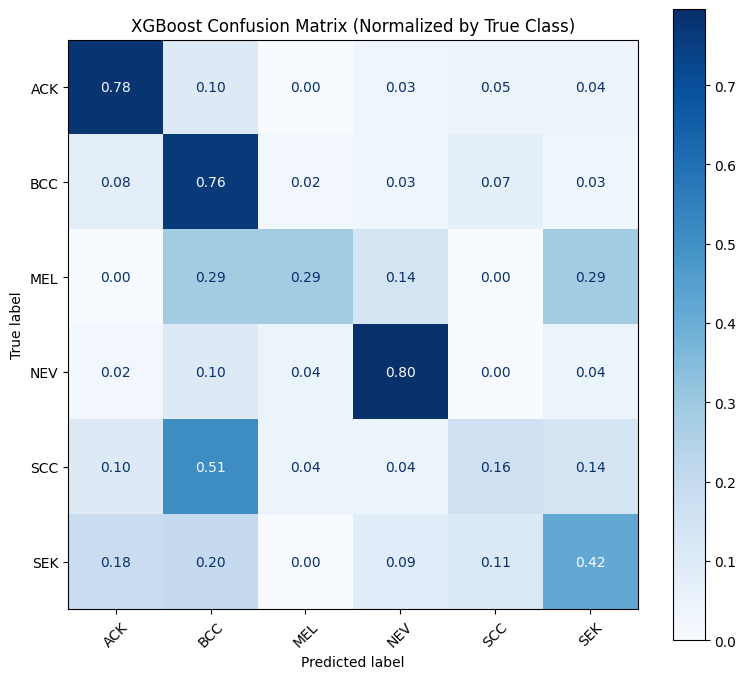

In [28]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm_norm = confusion_matrix(y_test, xgb_preds, normalize='true')

fig, ax = plt.subplots(figsize=(8,7))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=le.classes_)
disp.plot(ax=ax, cmap='Blues', values_format='.2f')
plt.title('XGBoost Confusion Matrix (Normalized by True Class)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [29]:
import os

def build_image_index(root_dir):
    index = {}
    for dirpath, dirnames, filenames in os.walk(root_dir):
        for fname in filenames:
            if fname.lower().endswith(('.png', '.jpg', '.jpeg')):
                index[fname] = os.path.join(dirpath, fname)
    return index

IMG_ROOT = r"D:\D DRIVE DOWNLOADS\zr7vgbcyr2-1\images"
img_index = build_image_index(IMG_ROOT)

print(len(img_index), "images indexed")
print(data['img_id'].isin(img_index.keys()).sum(), "of", len(data), "metadata rows have a matching image")

2298 images indexed
2298 of 2298 metadata rows have a matching image


In [30]:
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

class SkinLesionDataset(Dataset):
    def __init__(self, df, img_index, label_encoder, transform=None):
        self.df = df.reset_index(drop=True)
        self.img_index = img_index
        self.le = label_encoder
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img_path = self.img_index[row['img_id']]
        image = Image.open(img_path).convert('RGB')
        label = self.le.transform([row['diagnostic']])[0]
        if self.transform:
            image = self.transform(image)
        return image, label

In [31]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [32]:
train_img_ds = SkinLesionDataset(train_df, img_index, le, transform=train_transform)
test_img_ds = SkinLesionDataset(test_df, img_index, le, transform=test_transform)

train_img_loader = DataLoader(train_img_ds, batch_size=32, shuffle=True)
test_img_loader = DataLoader(test_img_ds, batch_size=32, shuffle=False)

print(len(train_img_ds), "training images,", len(test_img_ds), "test images")

1837 training images, 461 test images


In [33]:
train_img_loader = DataLoader(
    train_img_ds,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
    # persistent_workers removed
)

test_img_loader = DataLoader(
    test_img_ds,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
    # persistent_workers removed
)

In [34]:
preload_img_loader = DataLoader(
    train_img_ds,
    batch_size=32,
    shuffle=False,   # critical: keeps train_df row order intact
    num_workers=0,
    pin_memory=True
)

In [35]:
images, labels = next(iter(train_img_loader))
print("Batch image tensor shape:", images.shape)
print("Batch labels:", labels)

Batch image tensor shape: torch.Size([32, 3, 224, 224])
Batch labels: tensor([5, 1, 5, 1, 4, 0, 1, 1, 4, 1, 1, 0, 0, 0, 1, 1, 1, 0, 3, 1, 0, 0, 1, 1,
        5, 0, 1, 1, 1, 5, 1, 1])


In [36]:
#CNN  MODEL
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 28 * 28, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 224 -> 112
        x = self.pool(F.relu(self.conv2(x)))   # 112 -> 56
        x = self.pool(F.relu(self.conv3(x)))   # 56 -> 28
        x = x.view(x.size(0), -1)               # flatten
        x = F.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [37]:
from torchvision import models
import torch.nn as nn

efficientnet_model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

# freeze everything - we don't want to retrain the pretrained vision knowledge
for param in efficientnet_model.parameters():
    param.requires_grad = False

# EfficientNet's final layer currently outputs 1000 ImageNet classes - swap it for your 6
num_features = efficientnet_model.classifier[1].in_features
efficientnet_model.classifier[1] = nn.Linear(num_features, len(le.classes_))

efficientnet_model = efficientnet_model.to(device)

In [38]:
criterion_eff = nn.CrossEntropyLoss()
optimizer_eff = torch.optim.Adam(efficientnet_model.classifier.parameters(), lr=1e-4)

In [42]:
import os
import torch
import torch.nn as nn
from tqdm import tqdm
from torch.utils.data import TensorDataset, DataLoader
from torch.cuda.amp import autocast, GradScaler

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

efficientnet_model = efficientnet_model.to(device)

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

# ---- Preload images once, with disk caching ----
CACHE_DIR = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)

def preload_loader(loader, desc="Loading"):
    all_images, all_labels = [], []
    for images, labels in tqdm(loader, desc=desc):
        all_images.append(images)
        all_labels.append(labels)
    return torch.cat(all_images), torch.cat(all_labels)

def load_or_cache(loader, cache_name, desc="Loading"):
    path = os.path.join(CACHE_DIR, cache_name)
    if os.path.exists(path):
        print(f"Loading cached tensors from {path}")
        data = torch.load(path)
        return data["images"], data["labels"]
    else:
        images, labels = preload_loader(loader, desc)
        torch.save({"images": images, "labels": labels}, path)
        return images, labels

train_images_tensor, train_labels_tensor = load_or_cache(preload_img_loader, "train.pt", "Preloading train")
test_images_tensor, test_labels_tensor = load_or_cache(test_img_loader, "test.pt", "Preloading test")

fast_train_loader = DataLoader(TensorDataset(train_images_tensor, train_labels_tensor), batch_size=32, shuffle=True)
fast_test_loader = DataLoader(TensorDataset(test_images_tensor, test_labels_tensor), batch_size=32, shuffle=False)

print("Preloaded:", train_images_tensor.shape, test_images_tensor.shape)

# ---- Training ----
scaler = GradScaler()
num_epochs_eff = 15

for epoch in range(num_epochs_eff):
    efficientnet_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in fast_train_loader:
        images, labels = images.to(device, non_blocking=True), labels.to(device, non_blocking=True)

        optimizer_eff.zero_grad()

        with autocast():
            outputs = efficientnet_model(images)
            loss = criterion_eff(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer_eff)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs_eff} - Loss: {epoch_loss:.4f} - Train Accuracy: {epoch_acc:.4f}")

Using device: cuda
Loading cached tensors from cache\train.pt
Loading cached tensors from cache\test.pt
Preloaded: torch.Size([1837, 3, 224, 224]) torch.Size([461, 3, 224, 224])


D:\temp\ipykernel_14028\1200229651.py:47: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
D:\temp\ipykernel_14028\1200229651.py:61: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/15 - Loss: 1.3371 - Train Accuracy: 0.5139
Epoch 2/15 - Loss: 1.3013 - Train Accuracy: 0.5504
Epoch 3/15 - Loss: 1.2800 - Train Accuracy: 0.5433
Epoch 4/15 - Loss: 1.2550 - Train Accuracy: 0.5607
Epoch 5/15 - Loss: 1.2168 - Train Accuracy: 0.5765
Epoch 6/15 - Loss: 1.2017 - Train Accuracy: 0.5656
Epoch 7/15 - Loss: 1.1840 - Train Accuracy: 0.5879
Epoch 8/15 - Loss: 1.1562 - Train Accuracy: 0.6086
Epoch 9/15 - Loss: 1.1425 - Train Accuracy: 0.5988
Epoch 10/15 - Loss: 1.1329 - Train Accuracy: 0.6037
Epoch 11/15 - Loss: 1.1262 - Train Accuracy: 0.5874
Epoch 12/15 - Loss: 1.1098 - Train Accuracy: 0.6053
Epoch 13/15 - Loss: 1.0938 - Train Accuracy: 0.6059
Epoch 14/15 - Loss: 1.0854 - Train Accuracy: 0.6200
Epoch 15/15 - Loss: 1.0800 - Train Accuracy: 0.6140


In [43]:
from sklearn.metrics import classification_report

efficientnet_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in fast_test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = efficientnet_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=le.classes_))

KeyboardInterrupt: 

In [ ]:
from torchvision import models

vit_model = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)

# freeze everything, same reasoning as EfficientNet - keep the pretrained vision knowledge intact
for param in vit_model.parameters():
    param.requires_grad = False

# ViT's final layer is called 'heads', not 'classifier' like EfficientNet - swap it for your 6 classes
num_features = vit_model.heads.head.in_features
vit_model.heads.head = nn.Linear(num_features, len(le.classes_))

vit_model = vit_model.to(device)

In [ ]:
#Computing loss andweighting losses more for lesser sample data
import torch
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cnn_model = SimpleCNN(num_classes=len(le.classes_)).to(device)

train_labels_arr = train_df['diagnostic'].map(lambda x: le.transform([x])[0]).values
class_weights = compute_class_weight('balanced', classes=np.arange(len(le.classes_)), y=train_labels_arr)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(cnn_model.parameters(), lr=1e-4)

In [ ]:
criterion_vit = nn.CrossEntropyLoss(weight=class_weights)
optimizer_vit = torch.optim.Adam(vit_model.heads.parameters(), lr=1e-4)

In [ ]:
print(next(vit_model.parameters()).device)

cuda:0


In [ ]:
import torch
from torch.cuda.amp import autocast, GradScaler

torch.backends.cudnn.benchmark = True
torch.set_float32_matmul_precision("high")

scaler = GradScaler()
num_epochs_vit = 15

for epoch in range(num_epochs_vit):
    vit_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in fast_train_loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer_vit.zero_grad()

        with autocast():
            outputs = vit_model(images)
            loss = criterion_vit(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer_vit)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    print(f"Epoch {epoch+1}/{num_epochs_vit} - Loss: {epoch_loss:.4f} - Train Accuracy: {epoch_acc:.4f}")

D:\temp\ipykernel_10792\2769640163.py:7: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler()
D:\temp\ipykernel_10792\2769640163.py:22: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast():


Epoch 1/15 - Loss: 1.7903 - Train Accuracy: 0.2314
Epoch 2/15 - Loss: 1.6497 - Train Accuracy: 0.3555
Epoch 3/15 - Loss: 1.5428 - Train Accuracy: 0.4780
Epoch 4/15 - Loss: 1.4602 - Train Accuracy: 0.5329
Epoch 5/15 - Loss: 1.3952 - Train Accuracy: 0.5384
Epoch 6/15 - Loss: 1.3370 - Train Accuracy: 0.5721
Epoch 7/15 - Loss: 1.2885 - Train Accuracy: 0.5972
Epoch 8/15 - Loss: 1.2450 - Train Accuracy: 0.6151
Epoch 9/15 - Loss: 1.2075 - Train Accuracy: 0.6228
Epoch 10/15 - Loss: 1.1754 - Train Accuracy: 0.6075
Epoch 11/15 - Loss: 1.1457 - Train Accuracy: 0.6255
Epoch 12/15 - Loss: 1.1209 - Train Accuracy: 0.6385
Epoch 13/15 - Loss: 1.0976 - Train Accuracy: 0.6298
Epoch 14/15 - Loss: 1.0777 - Train Accuracy: 0.6364
Epoch 15/15 - Loss: 1.0577 - Train Accuracy: 0.6407


In [ ]:
from sklearn.metrics import classification_report

vit_model.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for images, labels in fast_test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = vit_model(images)
        _, predicted = torch.max(outputs, 1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(all_labels, all_preds, target_names=le.classes_))

              precision    recall  f1-score   support

         ACK       0.60      0.62      0.61       127
         BCC       0.68      0.56      0.61       174
         MEL       0.21      0.86      0.33         7
         NEV       0.69      0.51      0.59        49
         SCC       0.22      0.22      0.22        49
         SEK       0.53      0.69      0.60        55

    accuracy                           0.56       461
   macro avg       0.49      0.58      0.49       461
weighted avg       0.59      0.56      0.56       461



In [ ]:
import numpy as np

oof_data = np.load('oof_predictions.npz')
oof_xgb_probs = oof_data['xgb_probs']
oof_vit_probs = oof_data['vit_probs']
y_true = oof_data['y_true']

NUM_CLASSES = oof_xgb_probs.shape[1]

# Per-class recall for each model (accuracy restricted to samples of that true class)
xgb_class_recall = np.zeros(NUM_CLASSES)
vit_class_recall = np.zeros(NUM_CLASSES)

for c in range(NUM_CLASSES):
    mask = (y_true == c)
    xgb_class_recall[c] = (oof_xgb_probs[mask].argmax(1) == c).mean()
    vit_class_recall[c] = (oof_vit_probs[mask].argmax(1) == c).mean()

# Convert relative recall into a weight per class (higher recall = more trusted for that class)
eps = 1e-8
w_xgb = xgb_class_recall / (xgb_class_recall + vit_class_recall + eps)
w_vit = 1 - w_xgb

for c in range(NUM_CLASSES):
    print(f"Class {le.classes_[c]}: XGB recall={xgb_class_recall[c]:.2f}, "
          f"ViT recall={vit_class_recall[c]:.2f}  →  w_xgb={w_xgb[c]:.2f}, w_vit={w_vit[c]:.2f}")

Class ACK: XGB recall=0.78, ViT recall=0.77  →  w_xgb=0.50, w_vit=0.50
Class BCC: XGB recall=0.72, ViT recall=0.79  →  w_xgb=0.48, w_vit=0.52
Class MEL: XGB recall=0.38, ViT recall=0.02  →  w_xgb=0.94, w_vit=0.06
Class NEV: XGB recall=0.73, ViT recall=0.55  →  w_xgb=0.57, w_vit=0.43
Class SCC: XGB recall=0.23, ViT recall=0.00  →  w_xgb=1.00, w_vit=0.00
Class SEK: XGB recall=0.40, ViT recall=0.28  →  w_xgb=0.59, w_vit=0.41


In [ ]:
def class_weighted_fusion(xgb_probs, vit_probs, w_xgb, w_vit):
    # Elementwise weight each class's probability, then renormalize so it still sums to 1
    fused = xgb_probs * w_xgb[None, :] + vit_probs * w_vit[None, :]
    fused = fused / fused.sum(axis=1, keepdims=True)
    return fused

In [ ]:
from sklearn.metrics import classification_report

fused_oof = class_weighted_fusion(oof_xgb_probs, oof_vit_probs, w_xgb, w_vit)
fused_oof_preds = fused_oof.argmax(1)

print("=== Class-weighted fusion (OOF) ===")
print(classification_report(y_true, fused_oof_preds, target_names=le.classes_))

=== Class-weighted fusion (OOF) ===
              precision    recall  f1-score   support

         ACK       0.78      0.82      0.80       603
         BCC       0.72      0.76      0.74       671
         MEL       0.46      0.40      0.43        45
         NEV       0.75      0.77      0.76       195
         SCC       0.30      0.22      0.26       143
         SEK       0.54      0.42      0.47       180

    accuracy                           0.70      1837
   macro avg       0.59      0.57      0.58      1837
weighted avg       0.68      0.70      0.69      1837



In [ ]:
# Replace xgb_model / vit_model with your actual final trained model variable names
test_xgb_probs = xgb_model.predict_proba(X_test)   # X_test_full = your tabular test features

vit_model.eval()
test_vit_probs = []
with torch.no_grad():
    for images, _ in fast_test_loader:
        images = images.to(device)
        probs = torch.softmax(vit_model(images), dim=1)
        test_vit_probs.append(probs.cpu().numpy())
test_vit_probs = np.vstack(test_vit_probs)

fused_test = class_weighted_fusion(test_xgb_probs, test_vit_probs, w_xgb, w_vit)
fused_test_preds = fused_test.argmax(1)

print("=== Class-weighted fusion (TEST SET — final result) ===")
print(classification_report(y_test.values, fused_test_preds, target_names=le.classes_))

ValueError: operands could not be broadcast together with shapes (476,6) (461,6) 

In [ ]:
# --- Imports ---
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score
import torch
import torch.nn as nn

# --- Load data ---
data = pd.read_csv(r"D:\D DRIVE DOWNLOADS\zr7vgbcyr2-1\metadata.csv")

# Critical: keep the same patient ordering as the original notebook before splitting.
data = data.sort_values(by='patient_id').reset_index(drop=True)

# --- Your existing train/test split logic ---
features = ['grew', 'itch', 'changed', 'elevation', 'bleed', 'region', 'hurt', 'age']
target = 'diagnostic'

patients = data['patient_id'].unique()
patients = np.asarray(patients)
train_patients, test_patients = train_test_split(patients, test_size=0.2, random_state=42)

train_df = data[data['patient_id'].isin(train_patients)].copy()
test_df = data[data['patient_id'].isin(test_patients)].copy()

le = LabelEncoder()
train_df['target_enc'] = le.fit_transform(train_df[target])
test_df['target_enc'] = le.transform(test_df[target])

X_train = pd.get_dummies(train_df[features], dummy_na=True)
X_test = pd.get_dummies(test_df[features], dummy_na=True)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

y_train = train_df['target_enc']
y_test = test_df['target_enc']

print(X_train.shape, X_test.shape)

# --- Patient IDs for GroupKFold/GroupShuffleSplit ---
patient_ids_train = train_df['patient_id'].values

print("Setup complete:", train_df.shape, "| classes:", list(le.classes_))

(1822, 40) (476, 40)
Setup complete: (1822, 27) | classes: ['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']


In [ ]:
import numpy as np
import torch

# Rebuild the only two things the MLP step actually needs
patient_ids_train = train_df['patient_id'].values
NUM_CLASSES = len(le.classes_)

# Load the saved fold results into a distinct variable to avoid clobbering the DataFrame
oof_data = np.load('oof_predictions.npz')
oof_xgb_probs = oof_data['xgb_probs']
oof_vit_probs = oof_data['vit_probs']
y_true = oof_data['y_true']

print("Ready:", patient_ids_train.shape, oof_xgb_probs.shape, oof_vit_probs.shape)

Ready: (1822,) (1837, 6) (1837, 6)


In [ ]:
# Does img_index (or your original notebook) filter data before splitting?
# Check: does every patient_id in train_df actually have a matching image?
missing_images = [pid for pid in train_df['patient_id'] if pid not in img_index]  # adjust if img_index keys are img_id not patient_id
print(f"Rows without a matching image: {len(missing_images)}")

# Also just check raw counts
print("Raw data shape:", data.shape)
print("train_df shape:", train_df.shape)

Rows without a matching image: 1822


AttributeError: 'NpzFile' object has no attribute 'shape'

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, f1_score

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- Rebuild split at 90/10 instead of 80/20 ---
X_meta = np.concatenate([oof_xgb_probs, oof_vit_probs], axis=1)

gss = GroupShuffleSplit(n_splits=1, test_size=0.1, random_state=42)
meta_tr_idx, meta_val_idx = next(gss.split(X_meta, y_true, groups=patient_ids_train))

X_meta_tr, X_meta_val = X_meta[meta_tr_idx], X_meta[meta_val_idx]
y_meta_tr, y_meta_val = y_true[meta_tr_idx], y_true[meta_val_idx]

print(f"Meta-train: {len(X_meta_tr)}, Meta-val: {len(X_meta_val)}")
print("\nMeta-train class counts:")
for c, count in enumerate(np.bincount(y_meta_tr, minlength=NUM_CLASSES)):
    print(f"  {le.classes_[c]}: {count}")
print("\nMeta-val class counts:")
for c, count in enumerate(np.bincount(y_meta_val, minlength=NUM_CLASSES)):
    print(f"  {le.classes_[c]}: {count}")

# --- Weights, model, training (same as before) ---
class_counts = np.bincount(y_meta_tr, minlength=NUM_CLASSES)
class_weights_mlp = 1.0 / np.sqrt(class_counts + 1e-6)
class_weights_mlp = class_weights_mlp / class_weights_mlp.sum() * NUM_CLASSES
class_weights_mlp_t = torch.tensor(class_weights_mlp, dtype=torch.float32).to(device)

class MetaFusionMLP(nn.Module):
    def __init__(self, input_dim=12, hidden_dim=32, num_classes=6, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes)
        )
    def forward(self, x):
        return self.net(x)

model = MetaFusionMLP(input_dim=12, num_classes=NUM_CLASSES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss(weight=class_weights_mlp_t)

X_tr_t = torch.tensor(X_meta_tr, dtype=torch.float32)
y_tr_t = torch.tensor(y_meta_tr, dtype=torch.long)
X_val_t = torch.tensor(X_meta_val, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_meta_val, dtype=torch.long).to(device)

train_loader = DataLoader(TensorDataset(X_tr_t, y_tr_t), batch_size=64, shuffle=True)

best_val_f1 = 0
best_state = None
patience, patience_counter = 30, 0

for epoch in range(300):
    model.train()
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        out = model(xb)
        loss = criterion(out, yb)
        loss.backward()
        optimizer.step()

    model.eval()
    with torch.no_grad():
        val_out = model(X_val_t)
        val_preds = val_out.argmax(1).cpu().numpy()
        val_f1 = f1_score(y_meta_val, val_preds, average='macro', zero_division=0)
        val_acc = (val_out.argmax(1) == y_val_t).float().mean().item()
        num_classes_predicted = len(np.unique(val_preds))

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_state = model.state_dict()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}, best val macro-F1: {best_val_f1:.3f}")
            break

    if epoch % 10 == 0:
        print(f"Epoch {epoch} - Val Acc: {val_acc:.3f} - Val Macro-F1: {val_f1:.3f} - Classes predicted: {num_classes_predicted}/{NUM_CLASSES}")

model.load_state_dict(best_state)
model.eval()
with torch.no_grad():
    val_preds = model(X_val_t).argmax(1).cpu().numpy()

print(f"\nBest meta-val macro-F1: {best_val_f1:.3f}")
print("\n=== Meta-fusion MLP (90/10 split, dampened class weights) ===")
print(classification_report(y_meta_val, val_preds, target_names=le.classes_, zero_division=0))

ValueError: Found input variables with inconsistent numbers of samples: [1837, 1837, 1822]

In [ ]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.metrics import classification_report

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# --- Check class balance in meta-train first (worth seeing before retraining) ---
print("Meta-train class distribution:")
for c, count in enumerate(np.bincount(y_meta_tr, minlength=NUM_CLASSES)):
    print(f"  {le.classes_[c]}: {count} ({count/len(y_meta_tr)*100:.1f}%)")

# --- Class weights: rarer classes get penalized more heavily when wrong ---
class_counts = np.bincount(y_meta_tr, minlength=NUM_CLASSES)
class_weights = 1.0 / (class_counts + 1e-6)
class_weights = class_weights / class_weights.sum() * NUM_CLASSES  # normalize so avg weight ≈ 1
class_weights_t = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nClass weights (higher = penalized more when misclassified):")
for c in range(NUM_CLASSES):
    print(f"  {le.classes_[c]}: {class_weights[c]:.2f}")

# --- Fresh model + optimizer (don't resume from the collapsed one) ---
class MetaFusionMLP(nn.Module):
    def __init__(self, input_dim=12, hidden_dim=32, num_classes=6, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, num_classes)
        )
    def forward(self, x):
        return self.net(x)

model = MetaFusionMLP(input_dim=12, num_classes=NUM_CLASSES).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4, weight_decay=1e-4)  # lr lowered from 1e-3
criterion = nn.CrossEntropyLoss(weight=class_weights_t)  # <-- the actual fix

X_tr_t = torch.tensor(X_meta_tr, dtype=torch.float32).to(device)
y_tr_t = torch.tensor(y_meta_tr, dtype=torch.long).to(device)
X_val_t = torch.tensor(X_meta_val, dtype=torch.float32).to(device)
y_val_t = torch.tensor(y_meta_val, dtype=torch.long).to(device)

best_val_acc = 0
best_state = None
patience, patience_counter = 20, 0

for epoch in range(300):
    model.train()
    optimizer.zero_grad()
    out = model(X_tr_t)
    loss = criterion(out, y_tr_t)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_out = model(X_val_t)
        val_acc = (val_out.argmax(1) == y_val_t).float().mean().item()
        # Track per-class prediction diversity too, cheap way to catch collapse early
        num_classes_predicted = len(torch.unique(val_out.argmax(1)))

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = model.state_dict()
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= patience:
            print(f"Early stopping at epoch {epoch}, best val acc: {best_val_acc:.3f}")
            break

    if epoch % 50 == 0:
        print(f"Epoch {epoch} - Loss: {loss.item():.4f} - Val Acc: {val_acc:.3f} - Classes predicted: {num_classes_predicted}/{NUM_CLASSES}")

model.load_state_dict(best_state)
print(f"\nBest meta-val accuracy: {best_val_acc:.3f}")

# --- Detailed report ---
model.eval()
with torch.no_grad():
    val_preds = model(X_val_t).argmax(1).cpu().numpy()

print("\n=== Meta-fusion MLP (meta-validation, class-weighted) ===")
print(classification_report(y_meta_val, val_preds, target_names=le.classes_))